70/30 MSCI World / Emerging Markets backtest

The main strategy starts at 70% URTH (MSCI World) and 30% EEM (MSCI Emerging
Markets), then rebalances to those target weights once per calendar year.
A no-rebalancing version is included as a secondary comparison. ACWI is the
broad, market-cap-weighted global equity benchmark; a separate 70/30
benchmark with the same funds and rebalance rule would duplicate the strategy.

Adjusted closing prices are used as a proxy for total returns. The backtest
uses USD-listed ETFs, omits trading costs, taxes, and cash flows, and covers
January 2015 through October 2026.
The primary Sharpe ratio uses a date-matched 3-month U.S. Treasury yield from
FRED; a zero-risk-free-rate Sharpe ratio is also shown as a sensitivity check.

Historical sector and country allocations are not calculated because they
require historical holdings data. The final section shows current iShares
holdings snapshots instead.


In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.grid"] = True



In [2]:
START_DATE = "2015-01-01"
# yfinance treats `end` as exclusive; this includes data through 2026-10-31.
END_DATE = "2026-11-01"

WORLD_TICKER = "URTH"
EM_TICKER = "EEM"
BENCHMARK_TICKER = "ACWI"
FRED_RISK_FREE_SERIES = "DGS3MO"
TRADING_DAYS_PER_YEAR = 252
ROLLING_WINDOW = 252

STRATEGY_TICKERS = [WORLD_TICKER, EM_TICKER]
ALL_TICKERS = STRATEGY_TICKERS + [BENCHMARK_TICKER]
TARGET_WEIGHTS = pd.Series(
    {WORLD_TICKER: 0.70, EM_TICKER: 0.30},
    dtype=float,
)



In [3]:
raw = yf.download(
    ALL_TICKERS,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False,
)

if raw.empty:
    raise RuntimeError("Yahoo Finance returned no price data for the selected tickers and dates.")

if isinstance(raw.columns, pd.MultiIndex):
    close_level = next(
        (
            level
            for level in range(raw.columns.nlevels)
            if "Close" in raw.columns.get_level_values(level)
        ),
        None,
    )
    if close_level is None:
        raise KeyError("The downloaded data has no Close price column.")
    prices = raw.xs("Close", axis=1, level=close_level)
else:
    if "Close" not in raw.columns:
        raise KeyError("The downloaded data has no Close price column.")
    prices = raw[["Close"]].rename(columns={"Close": ALL_TICKERS[0]})

missing_tickers = sorted(set(ALL_TICKERS) - set(prices.columns))
if missing_tickers:
    raise KeyError(f"Price data is missing ticker(s): {', '.join(missing_tickers)}")

# Keep only dates with prices for every ETF so comparisons use identical dates.
prices = prices.reindex(columns=ALL_TICKERS).dropna(how="any")
if len(prices) < 2:
    raise RuntimeError("At least two common price dates are required for the backtest.")

print(f"Using {prices.index[0].date()} to {prices.index[-1].date()} ({len(prices)} trading days).")
print(prices.head())



Using 2015-01-02 to 2026-10-30 (2975 trading days).
Ticker           URTH        EEM       ACWI
Date                                       
2015-01-02  57.947815  30.198093  46.700165
2015-01-05  56.589108  29.660646  45.779926
2015-01-06  55.836956  29.536018  45.307789
2015-01-07  56.403095  30.174711  45.899956
2015-01-08  57.656681  30.688795  46.620136


In [4]:
# FRED reports DGS3MO as an annualized percent yield. Convert the previous
# trading day's yield into an approximate return over each price interval.
fred_url = (
    "https://fred.stlouisfed.org/graph/fredgraph.csv"
    f"?id={FRED_RISK_FREE_SERIES}&cosd={START_DATE}&coed={END_DATE}"
)
risk_free_data = pd.read_csv(fred_url, index_col=0, parse_dates=True)
if FRED_RISK_FREE_SERIES not in risk_free_data.columns:
    raise KeyError(f"FRED data is missing series {FRED_RISK_FREE_SERIES}.")

risk_free_yield = pd.to_numeric(
    risk_free_data[FRED_RISK_FREE_SERIES],
    errors="coerce",
).dropna()
if risk_free_yield.empty:
    raise RuntimeError("FRED returned no observations for the risk-free rate series.")

risk_free_yield = risk_free_yield.sort_index().reindex(prices.index).ffill()
if risk_free_yield.isna().any():
    raise RuntimeError("FRED risk-free rate data does not cover the backtest start date.")

calendar_days = prices.index.to_series().diff().dt.days
daily_risk_free_returns = (
    (1 + risk_free_yield.shift(1) / 100)
    ** (calendar_days / 365.25)
    - 1
).dropna()
daily_risk_free_returns.name = "3-month Treasury risk-free return"



In [5]:
def simulate_portfolio(
    asset_returns: pd.DataFrame,
    target_weights: pd.Series,
    rebalance_annually: bool,
) -> tuple[pd.Series, pd.DataFrame]:
    """Simulate daily portfolio returns and closing weights from daily asset returns."""
    weights = target_weights.astype(float).copy()
    portfolio_returns = []
    closing_weights = []

    for position, (date, daily_asset_returns) in enumerate(asset_returns.iterrows()):
        day_returns = daily_asset_returns[target_weights.index]
        portfolio_return = float((weights * day_returns).sum())
        end_values = weights * (1 + day_returns)
        weights = end_values / (1 + portfolio_return)

        if (
            rebalance_annually
            and position + 1 < len(asset_returns)
            and asset_returns.index[position + 1].year != date.year
        ):
            # Rebalance at this calendar-year close for the next year's returns.
            weights = target_weights.astype(float).copy()

        portfolio_returns.append(portfolio_return)
        closing_weights.append(weights.copy())

    returns = pd.Series(
        portfolio_returns,
        index=asset_returns.index,
        name="Portfolio return",
    )
    weights_over_time = pd.DataFrame(closing_weights, index=asset_returns.index)
    weights_over_time.columns = target_weights.index
    return returns, weights_over_time


def equity_curve_from_returns(returns: pd.Series, initial_date: pd.Timestamp) -> pd.Series:
    """Create a growth-of-one series with an initial value on the first price date."""
    growth = (1 + returns).cumprod()
    initial_value = pd.Series([1.0], index=pd.DatetimeIndex([initial_date]))
    return pd.concat([initial_value, growth]).rename(returns.name)


asset_returns = prices[STRATEGY_TICKERS].pct_change().dropna()
strategy_returns, strategy_weights = simulate_portfolio(
    asset_returns,
    TARGET_WEIGHTS,
    rebalance_annually=True,
)
buy_and_hold_returns, buy_and_hold_weights = simulate_portfolio(
    asset_returns,
    TARGET_WEIGHTS,
    rebalance_annually=False,
)

strategy_value = equity_curve_from_returns(strategy_returns, prices.index[0]).rename(
    "70/30 Annual Rebalance"
)
buy_and_hold_value = equity_curve_from_returns(
    buy_and_hold_returns,
    prices.index[0],
).rename("70/30 Buy-and-Hold")
benchmark_returns = prices[BENCHMARK_TICKER].pct_change().dropna()
benchmark_value = equity_curve_from_returns(
    benchmark_returns,
    prices.index[0],
).rename("MSCI ACWI (ACWI)")

equity_curves = pd.concat(
    [strategy_value, buy_and_hold_value, benchmark_value],
    axis="columns",
    sort=False,
)

# Include target weights at inception in the displayed weight histories.
initial_weights_row = pd.DataFrame(
    [TARGET_WEIGHTS],
    index=pd.DatetimeIndex([prices.index[0]]),
)
strategy_weights = pd.concat([initial_weights_row, strategy_weights])
buy_and_hold_weights = pd.concat([initial_weights_row, buy_and_hold_weights])



In [6]:
def performance_metrics(equity_curve: pd.Series, benchmark: pd.Series | None = None) -> pd.Series:
    returns = equity_curve.pct_change().dropna()
    years = (equity_curve.index[-1] - equity_curve.index[0]).days / 365.25
    daily_volatility = returns.std(ddof=1)

    if years <= 0:
        raise ValueError("The backtest needs prices covering more than one calendar day.")

    returns_with_risk_free = pd.concat(
        [
            returns.rename("portfolio"),
            daily_risk_free_returns.reindex(returns.index).rename("risk_free"),
        ],
        axis="columns",
        sort=False,
    ).dropna()
    excess_returns = returns_with_risk_free["portfolio"] - returns_with_risk_free["risk_free"]
    sharpe_ratio = (
        excess_returns.mean() / daily_volatility * np.sqrt(TRADING_DAYS_PER_YEAR)
        if daily_volatility > 0 and not excess_returns.empty
        else np.nan
    )
    zero_risk_free_sharpe = (
        returns.mean() / daily_volatility * np.sqrt(TRADING_DAYS_PER_YEAR)
        if daily_volatility > 0
        else np.nan
    )
    metrics = {
        "Cumulative return": equity_curve.iloc[-1] / equity_curve.iloc[0] - 1,
        "CAGR": (equity_curve.iloc[-1] / equity_curve.iloc[0]) ** (1 / years) - 1,
        "Annualized volatility": daily_volatility * np.sqrt(TRADING_DAYS_PER_YEAR),
        "Sharpe ratio (3-month Treasury)": sharpe_ratio,
        "Sharpe ratio (0% risk-free sensitivity)": zero_risk_free_sharpe,
        "Maximum drawdown": (equity_curve / equity_curve.cummax() - 1).min(),
    }

    if benchmark is not None:
        aligned_returns = pd.concat(
            [returns.rename("strategy"), benchmark.pct_change().rename("benchmark")],
            axis="columns",
            sort=False,
        ).dropna()
        active_returns = aligned_returns["strategy"] - aligned_returns["benchmark"]
        tracking_error = active_returns.std(ddof=1) * np.sqrt(TRADING_DAYS_PER_YEAR)
        metrics["Annualized active return"] = active_returns.mean() * TRADING_DAYS_PER_YEAR
        metrics["Tracking error"] = tracking_error
        metrics["Information ratio"] = (
            active_returns.mean() / active_returns.std(ddof=1) * np.sqrt(TRADING_DAYS_PER_YEAR)
            if active_returns.std(ddof=1) > 0
            else np.nan
        )

    return pd.Series(metrics)


metrics = pd.DataFrame(
    {
        "70/30 Annual Rebalance": performance_metrics(strategy_value, benchmark_value),
        "70/30 Buy-and-Hold": performance_metrics(buy_and_hold_value, benchmark_value),
        "MSCI ACWI (ACWI)": performance_metrics(benchmark_value),
    }
)

percentage_metrics = [
    "Cumulative return",
    "CAGR",
    "Annualized volatility",
    "Maximum drawdown",
    "Annualized active return",
    "Tracking error",
]
formatted_metrics = metrics.astype(object)
for metric in percentage_metrics:
    if metric in metrics.index:
        formatted_metrics.loc[metric] = metrics.loc[metric].map(
            lambda value: f"{value:.2%}" if pd.notna(value) else "N/A"
        )
for metric in [
    "Sharpe ratio (3-month Treasury)",
    "Sharpe ratio (0% risk-free sensitivity)",
    "Information ratio",
]:
    if metric in metrics.index:
        formatted_metrics.loc[metric] = metrics.loc[metric].map(
            lambda value: f"{value:.2f}" if pd.notna(value) else "N/A"
        )

print("Performance metrics (primary Sharpe uses the daily 3-month Treasury yield):")
print(formatted_metrics)



Performance metrics (primary Sharpe uses the daily 3-month Treasury yield):
                                        70/30 Annual Rebalance  \
Annualized active return                                -0.73%   
Annualized volatility                                   17.38%   
CAGR                                                     9.84%   
Cumulative return                                      203.25%   
Information ratio                                        -0.23   
Maximum drawdown                                       -33.50%   
Sharpe ratio (0% risk-free sensitivity)                   0.63   
Sharpe ratio (3-month Treasury)                           0.51   
Tracking error                                           3.15%   

                                        70/30 Buy-and-Hold MSCI ACWI (ACWI)  
Annualized active return                            -0.62%              N/A  
Annualized volatility                               17.28%           16.87%  
CAGR                         

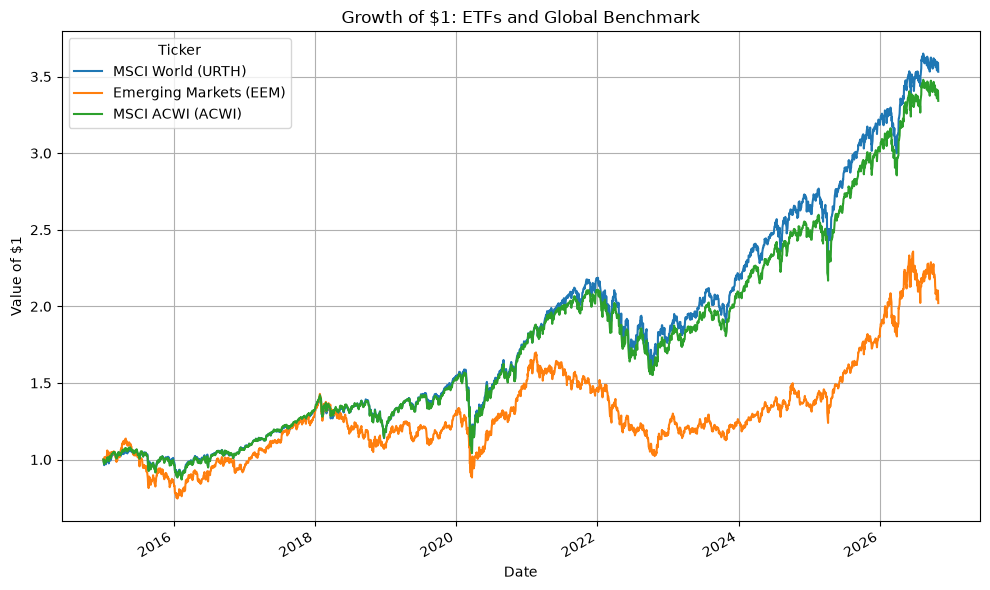

In [7]:
# Cumulative growth of $1 in each ETF and the broad-market benchmark.
growth_of_one = prices.div(prices.iloc[0])
growth_of_one.rename(
    columns={
        WORLD_TICKER: "MSCI World (URTH)",
        EM_TICKER: "Emerging Markets (EEM)",
        BENCHMARK_TICKER: "MSCI ACWI (ACWI)",
    }
).plot()
plt.title("Growth of $1: ETFs and Global Benchmark")
plt.ylabel("Value of $1")
plt.xlabel("Date")
plt.tight_layout()
plt.show()



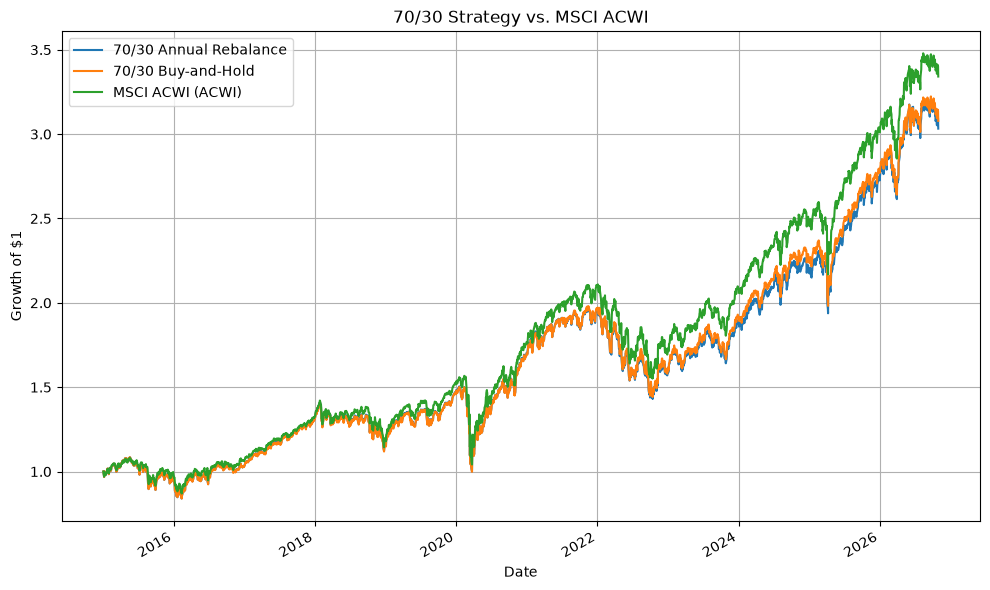

In [8]:
equity_curves.plot()
plt.title("70/30 Strategy vs. MSCI ACWI")
plt.ylabel("Growth of $1")
plt.xlabel("Date")
plt.tight_layout()
plt.show()



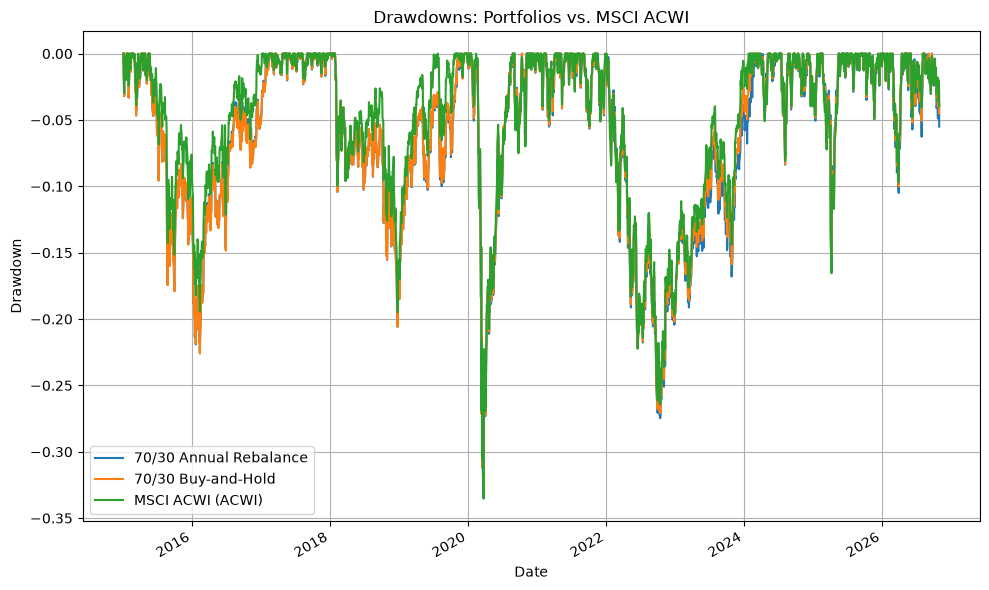

In [9]:
drawdowns = equity_curves.div(equity_curves.cummax()) - 1
drawdowns.plot()
plt.title("Drawdowns: Portfolios vs. MSCI ACWI")
plt.ylabel("Drawdown")
plt.xlabel("Date")
plt.tight_layout()
plt.show()



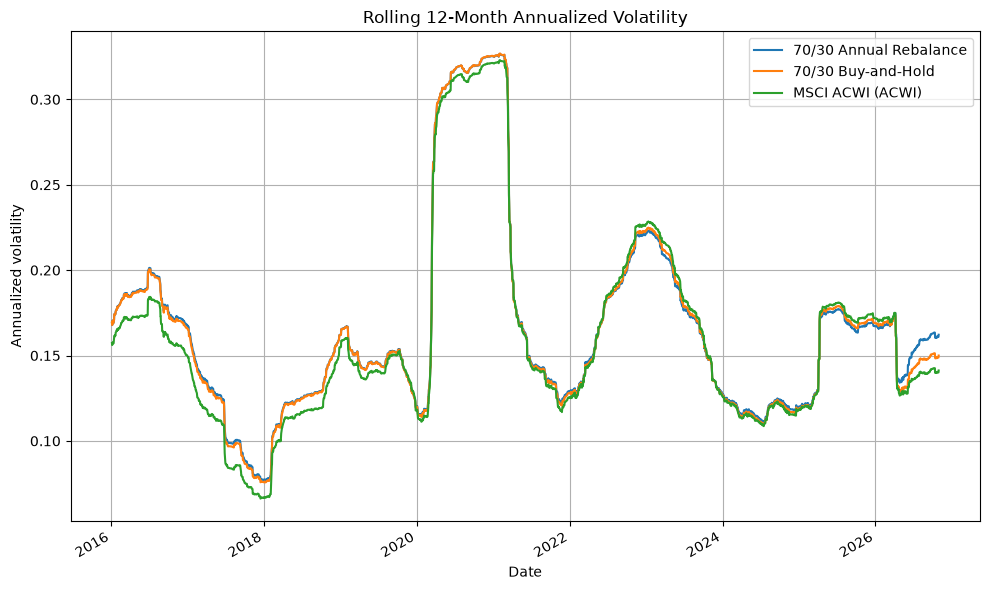

In [10]:
comparison_returns = pd.concat(
    {
        "70/30 Annual Rebalance": strategy_returns,
        "70/30 Buy-and-Hold": buy_and_hold_returns,
        "MSCI ACWI (ACWI)": benchmark_returns,
    },
    axis="columns",
    sort=False,
).dropna()
rolling_volatility = (
    comparison_returns.rolling(ROLLING_WINDOW).std() * np.sqrt(TRADING_DAYS_PER_YEAR)
)
rolling_volatility.plot()
plt.title("Rolling 12-Month Annualized Volatility")
plt.ylabel("Annualized volatility")
plt.xlabel("Date")
plt.tight_layout()
plt.show()



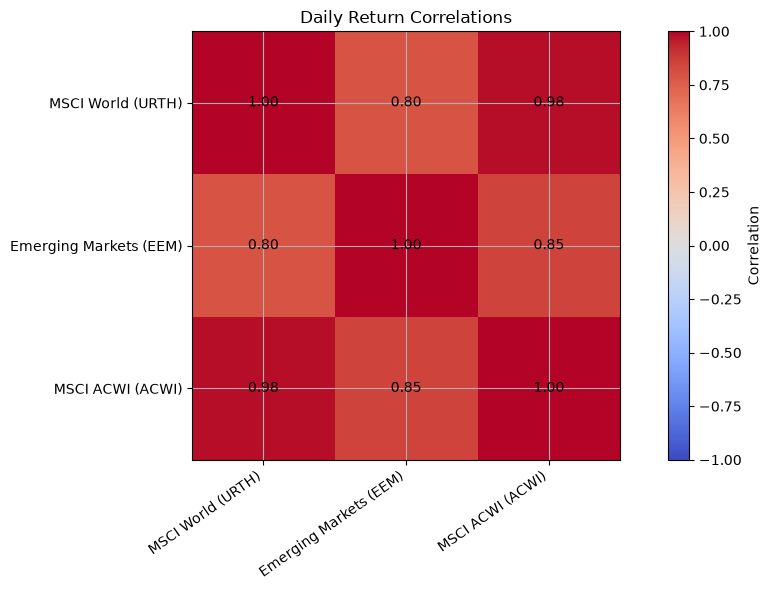

In [11]:
asset_and_benchmark_returns = pd.concat(
    [asset_returns, benchmark_returns.rename(BENCHMARK_TICKER)],
    axis="columns",
    sort=False,
).rename(
    columns={
        WORLD_TICKER: "MSCI World (URTH)",
        EM_TICKER: "Emerging Markets (EEM)",
        BENCHMARK_TICKER: "MSCI ACWI (ACWI)",
    }
)
correlations = asset_and_benchmark_returns.corr()

fig, ax = plt.subplots()
image = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(
    range(len(correlations.columns)),
    labels=correlations.columns,
    rotation=35,
    ha="right",
)
ax.set_yticks(range(len(correlations.index)), labels=correlations.index)
for row in range(len(correlations.index)):
    for column in range(len(correlations.columns)):
        ax.text(
            column,
            row,
            f"{correlations.iloc[row, column]:.2f}",
            ha="center",
            va="center",
        )
fig.colorbar(image, ax=ax, label="Correlation")
ax.set_title("Daily Return Correlations")
fig.tight_layout()
plt.show()



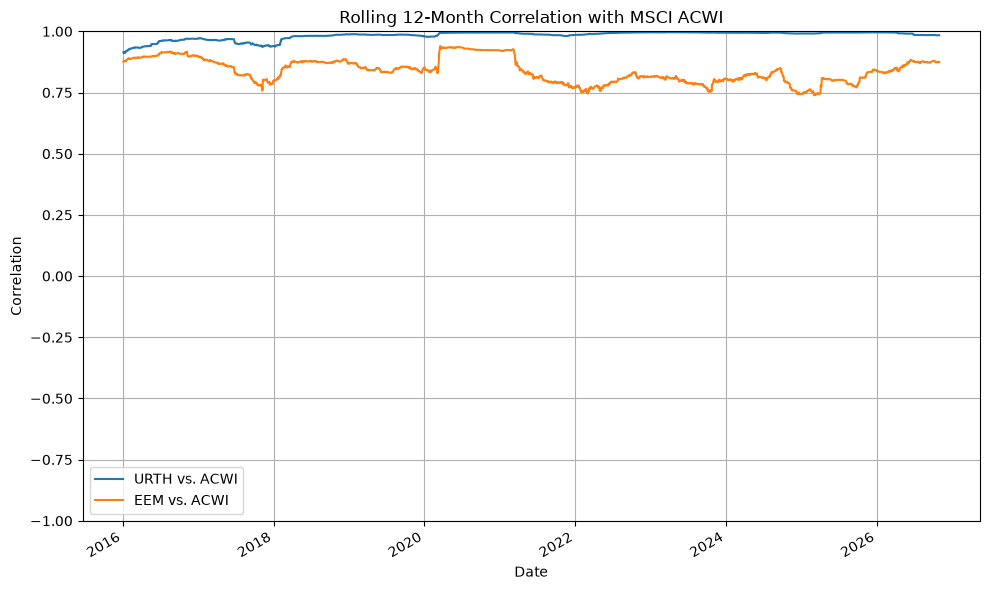

In [12]:
rolling_correlations = pd.DataFrame(
    {
        "URTH vs. ACWI": asset_returns[WORLD_TICKER].rolling(ROLLING_WINDOW).corr(
            benchmark_returns
        ),
        "EEM vs. ACWI": asset_returns[EM_TICKER].rolling(ROLLING_WINDOW).corr(
            benchmark_returns
        ),
    }
)
rolling_correlations.plot()
plt.title("Rolling 12-Month Correlation with MSCI ACWI")
plt.ylabel("Correlation")
plt.xlabel("Date")
plt.ylim(-1, 1)
plt.tight_layout()
plt.show()



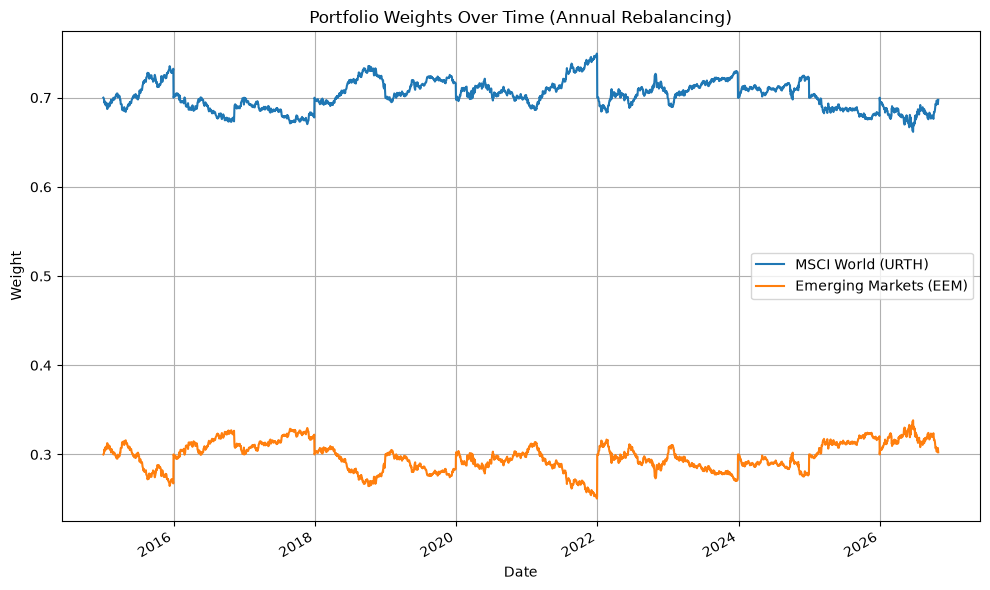

In [13]:
strategy_weights.rename(
    columns={
        WORLD_TICKER: "MSCI World (URTH)",
        EM_TICKER: "Emerging Markets (EEM)",
    }
).plot()
plt.title("Portfolio Weights Over Time (Annual Rebalancing)")
plt.ylabel("Weight")
plt.xlabel("Date")
plt.tight_layout()
plt.show()



In [14]:
# Calendar-year returns make annual performance comparisons easy to report.
calendar_year_returns = comparison_returns.groupby(comparison_returns.index.year).apply(
    lambda year_returns: (1 + year_returns).prod() - 1
)
last_data_year = prices.index[-1].year
if prices.index[-1].month < 12:
    calendar_year_returns.index = [
        f"{year}*" if year == last_data_year else str(year)
        for year in calendar_year_returns.index
    ]
else:
    calendar_year_returns.index = calendar_year_returns.index.astype(str)
calendar_year_returns.index.name = "Year"
print("Calendar-year returns:")
print(calendar_year_returns.to_string(float_format=lambda value: f"{value:.2%}"))
if prices.index[-1].month < 12:
    print(f"* Partial year through {prices.index[-1].date()}.")


Calendar-year returns:
       70/30 Annual Rebalance  70/30 Buy-and-Hold  MSCI ACWI (ACWI)
Year                                                               
2015                   -4.95%              -4.95%            -1.97%
2016                    8.37%               8.26%             8.40%
2017                   27.24%              26.88%            24.33%
2018                  -10.59%             -10.57%            -9.12%
2019                   25.17%              25.35%            26.59%
2020                   16.16%              16.11%            16.34%
2021                   14.50%              15.35%            18.66%
2022                  -18.75%             -18.55%           -18.39%
2023                   19.45%              20.68%            22.27%
2024                   15.01%              16.27%            17.45%
2025                   25.15%              23.63%            22.41%
2026*                  11.27%              11.14%            11.00%
* Partial year through 20

## Regional context and current holdings

These exhibits adapt the Group AL holdings-based geography and sector views to the current 70/30 strategy. They are current snapshots, not historical backtest results. The GDP-share trend and GDP/market-cap comparison are separate explanatory analyses; the 70/30 target is not applied to GDP totals. Holdings are dated November 25, 2026. Run the next cell to refresh the regional tables and charts from the supplied data files.

Holdings snapshots: World Nov 25, 2026; Emerging Markets Nov 25, 2026.
Regional GDP/cap shares use 23 developed and 24 emerging-market countries; excluded EEM residual weight: 0.00003%.
Weighted equity exposure: 99.794% of NAV; cash/derivative residual: 0.206%.
                                       Measure              Year or holdings date  Developed-market share (%)  Emerging-market share (%)             Countries with data                                                                                                                                                                                                                                                                                                                                                                                            Coverage note
                          Portfolio EEM sleeve Nov 25, 2026 (World: Nov 25, 2026)                   70.000000                  30.000000            2 ETF holdings files        

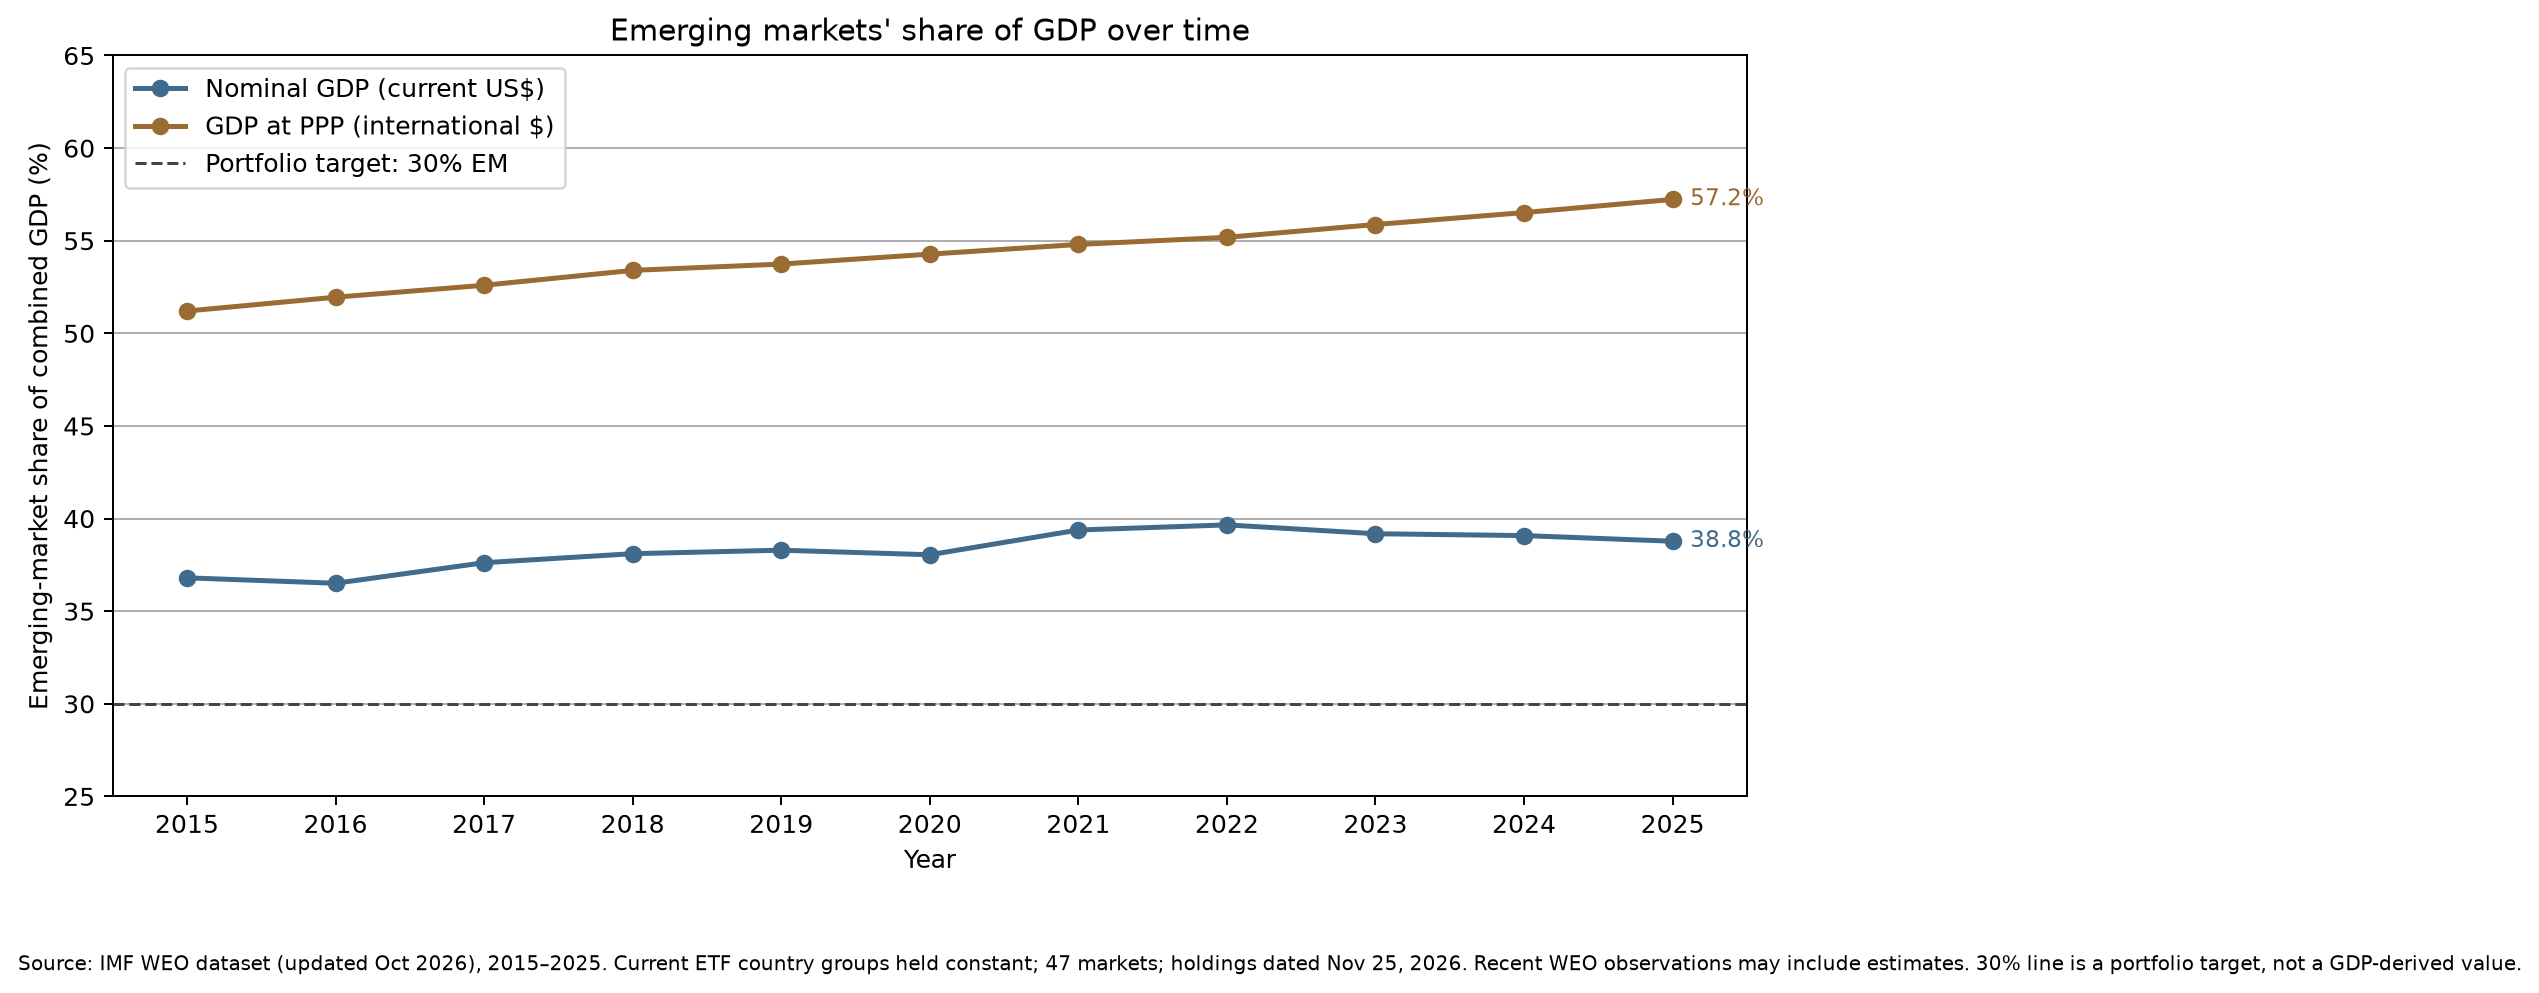

GDP and market-cap comparison


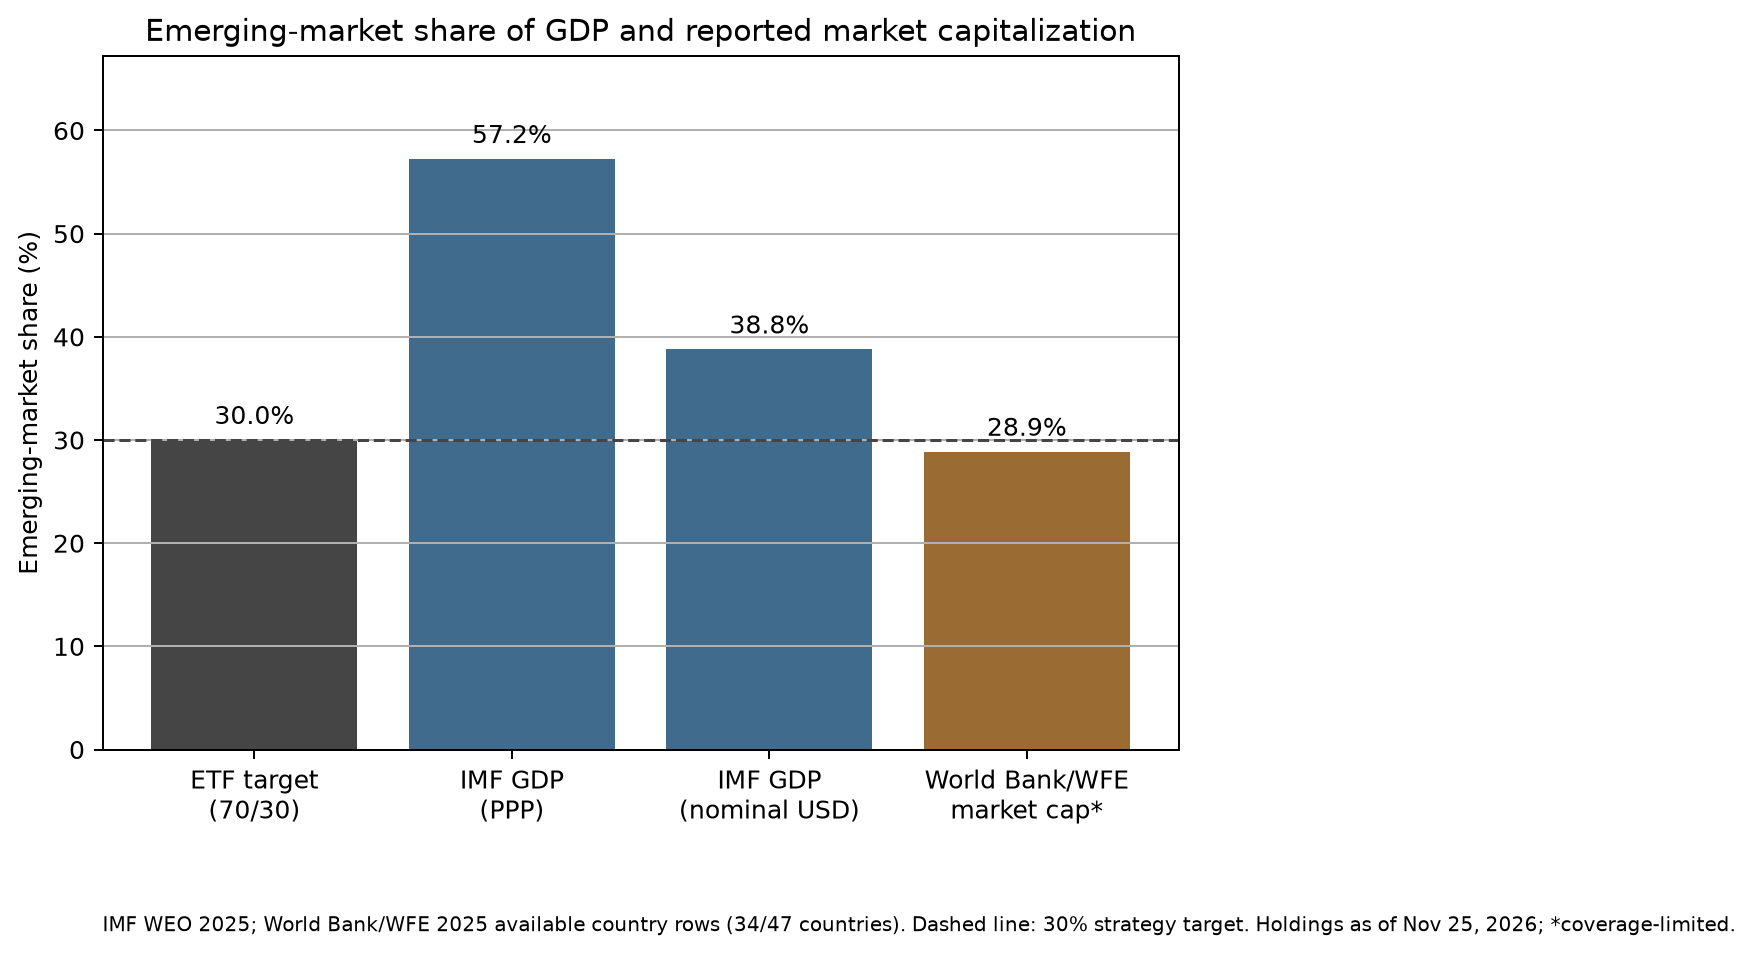

Current country exposures


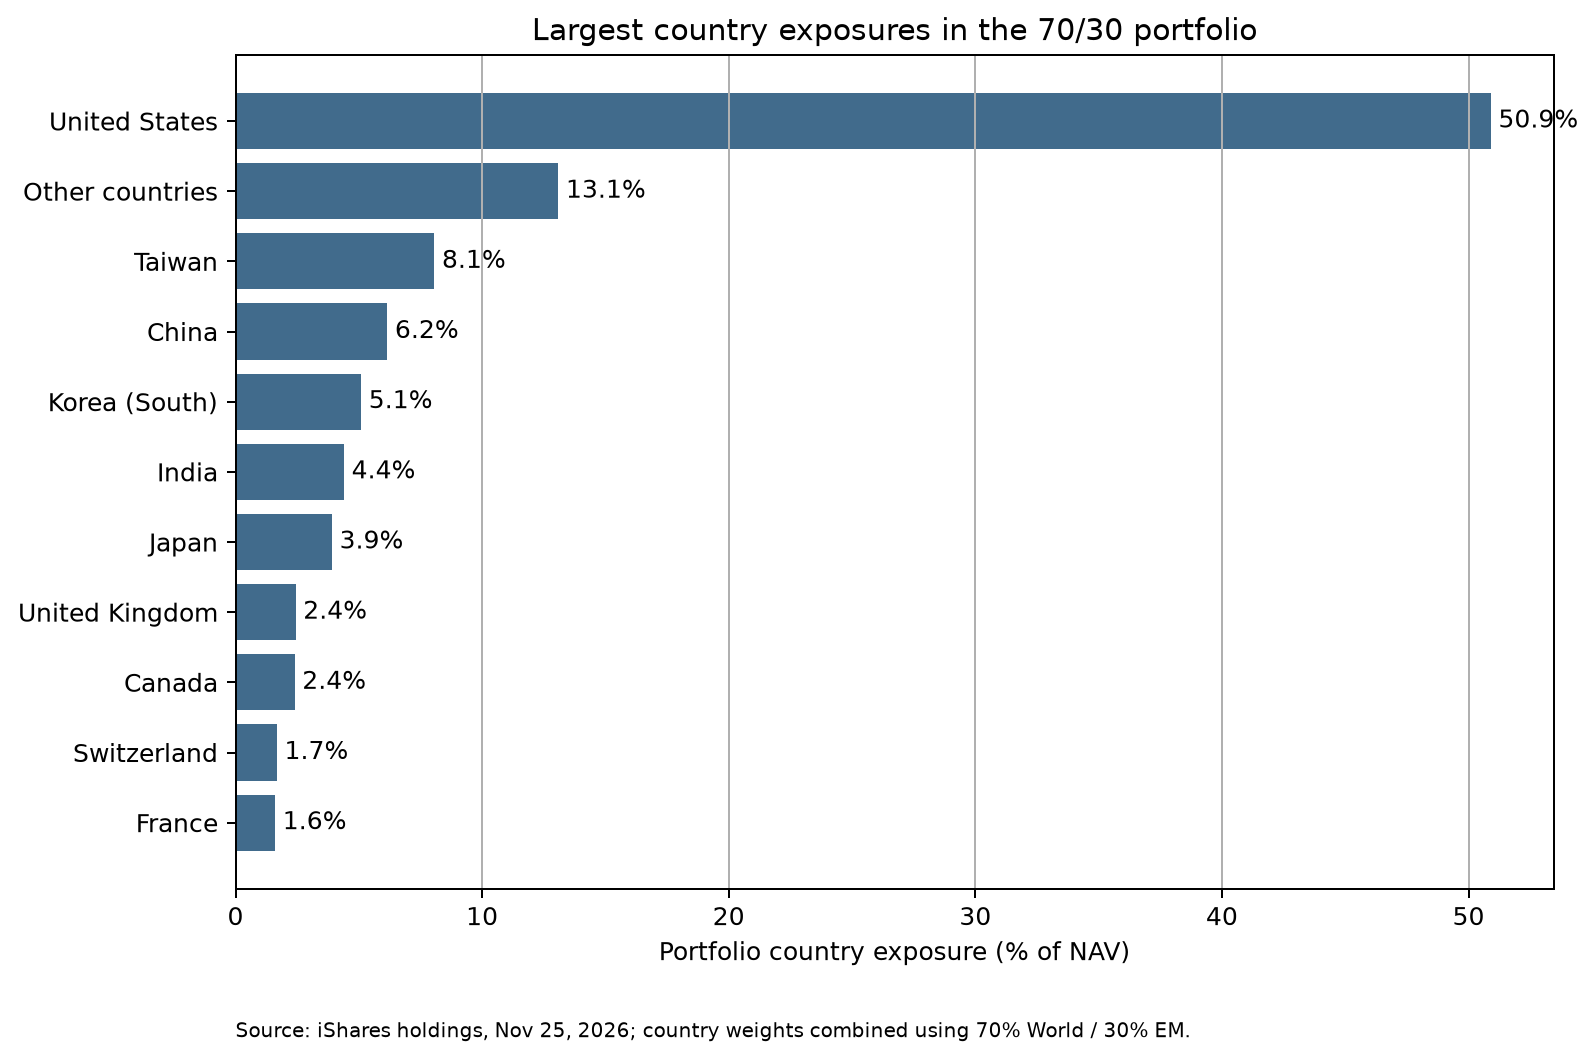

Current sector exposures


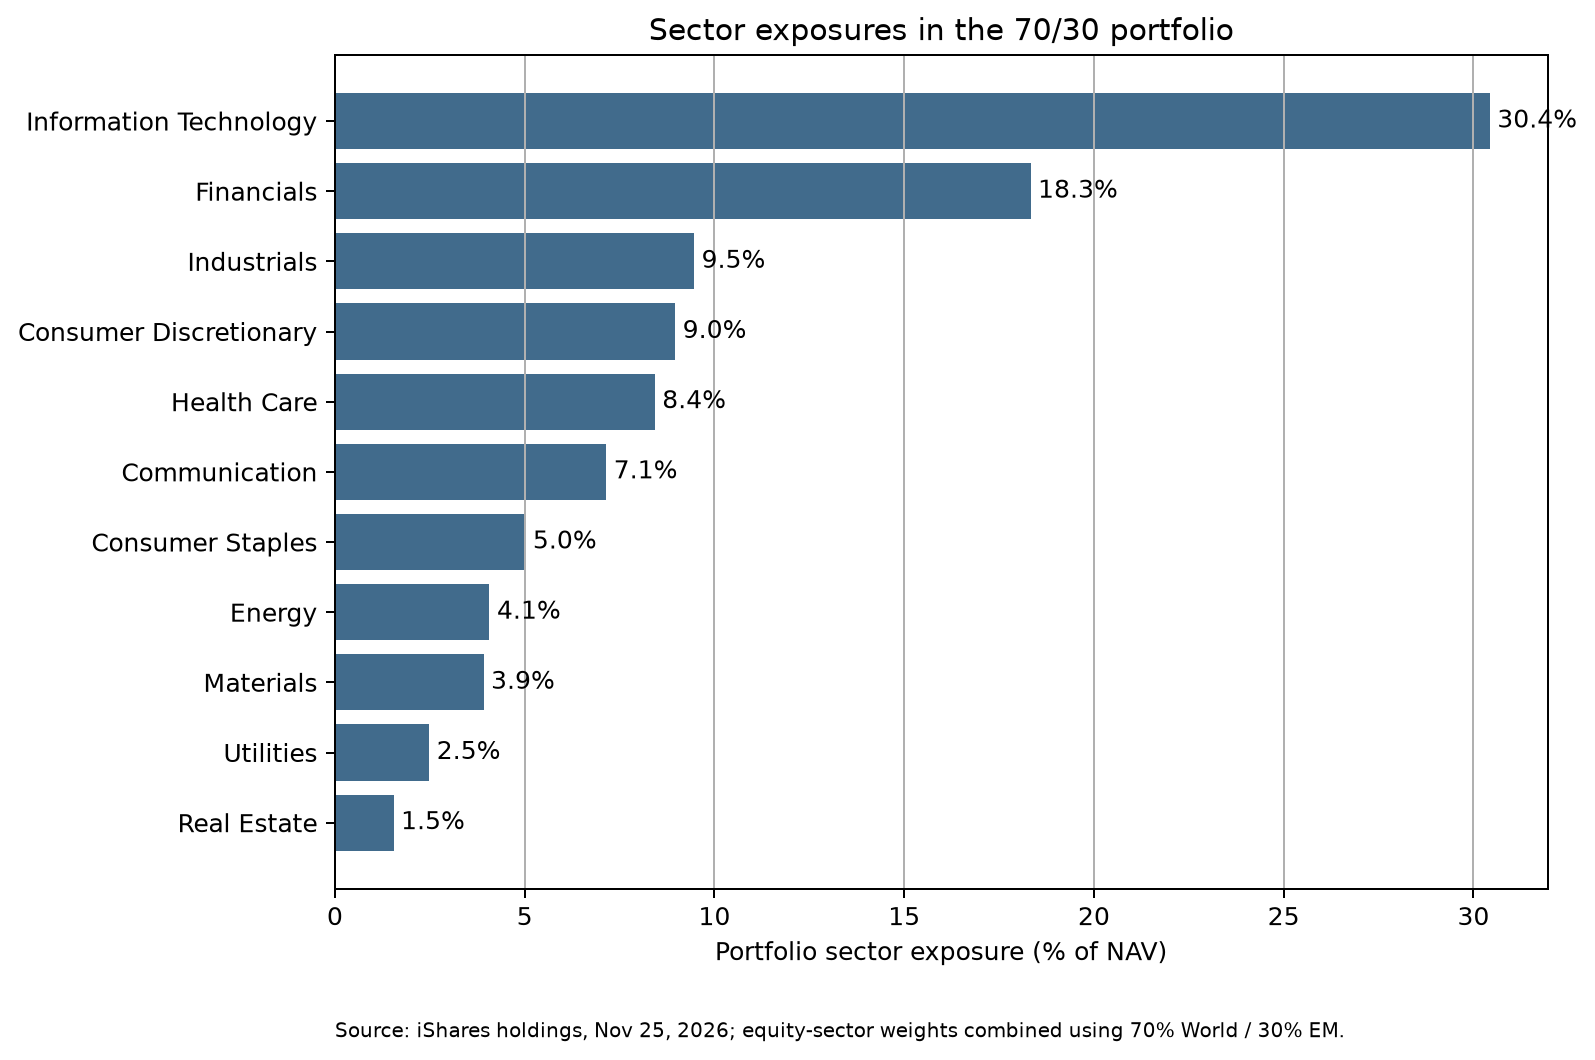

In [15]:
from pathlib import Path
from runpy import run_path
from IPython.display import Image, display

analysis_script = Path.cwd() / "regional_weighting_analysis.py"
if not analysis_script.is_file():
    raise FileNotFoundError(
        "Run this notebook from the project directory containing regional_weighting_analysis.py."
    )

regional_analysis = run_path(str(analysis_script))
regional_analysis["main"]()

for title, filename in [
    ("GDP share trend", "gdp_share_trend.png"),
    ("GDP and market-cap comparison", "regional_weighting_comparison.png"),
    ("Current country exposures", "portfolio_country_allocation.png"),
    ("Current sector exposures", "portfolio_sector_allocation.png"),
]:
    print(title)
    display(Image(filename=str(analysis_script.parent / filename)))
